---
---

<h1><center><ins>Numerical Methods: Exam 1</ins></center></h1>
<h2><center>November 17, 09:45-11:15 </center></h2>

Please answer the short questions related to the numerical methods we discussed during the lectures. Provide short and concise (one-two sentences) answers.

Pleasecompute the below questions in the python notebook, *documenting your code* where needed, or create .py files that are documented.

Remember also to **_answer any discussion points asked in the question_**.  

***Before 11:20*** your files need to be uploaded to GitHub.<br>
<br>
This means you have roughly 90 minutes to complete the exercises in this part.

You may use the lecture notes and any of your exercises freely, but you can **not** use ChatGPT code assistant or other AI coding tools such as Claude.<br> 
**_Collaboration or plagarized code except your own is prohibited and no phones or communication will be allowed_**.

---
---

## Short questions
1. Is the symmetrical or non-symmetrical version of the numerical derivative more precise? Why is one of the way of calculating it more precise than the other from the mathematical points of view? (**2 points**)
2. What is the difference between 1/3 and 3/8 Simpson's rules of numerical integration? Which rule usually has higher precision? (**2 points**)
3. Describe in a sentence or two what is the main difference between the Hermite Taylor and the spline interpolations. Does using higher degrees of polinomial interpolation always improves the precision? (**2 points**)
4. What is the difference between an interpolating, approximating, and extrapolating function? (**2 points**)
5. What are the typical methods of solving the systems of non-linear equations? Is a general solution usually possible? (**2 points**)

1. the symmetrical method is way more accurate due to the fact it uses points on both sides. This cancels out some of the errors and so making the result more precise and accurate instead of when just using the non symmetrical method.
2. simpsons 1/3 rule uses two intervals and a quadratic polynomial. while the 3/8 simpsons rule uses three intervals and a cubic polynomial. Both are very accurate but the 1/3 rule is slightly more precise if we are using same step size
3. taylor uses derivatives at one point and Hermite uses values and derivatives at several points where splines connect smaller polynomials more smoothly. but higher-degree polynomials are not always better. Sometimes they can cause unwanted oscillations which we dont want.

4.     
* interpolation: the function estimates values between known data points and reproduces the given data points
* approximation: estimates the general trend of data without really passing through every point
* extrapolation: function predicts values outside the known/given data range

(interpolation is useful for missing data, while approximation is useful for smoothing noisy data)

5.  to solve non linear systems we ussually solved them with iterative methods, like the newton raphson. A general solution is probably not possible due to the result depending on the starting point and the convergence is not guaranteed. For example newton raphson can fail if the initial guess is too far from the root.


## Exercise 1. Calculate the mass of the Sun (10 Points)

Internal structure of stars can be described by a set of equations including the mass continuity equation. The density inside the Sun can be described in a simplified way by the following polynomial:

$$
d(x) = 
519x^4 - 1630x^3 + 1844x^2 - 889x + 155
$$

Here, x is the dimensionless solar radius $x = R/R_\odot$ that goes from 0 at the centre to 1 at the Sun's surface. The density is in g/cm$³$. The solar radius $R_\odot =  6.9 \times 10^{10}$ cm. 

**(a)** Create the integrand that you would use to calculate the Sun's mass using the density profile given above. Hint: don't forget that you need to intergrate  the spherical coordinate system (**1 point**)

**(b)** Numerically integrate the mass continuity equation for the Sun that uses the density profile given above using the Simpson's 1/3 rule (**5 points** is you use your own implementation of the algorithm, **1 point** if you use an embedded function)

(NB: your result will be somewhat different from the precise solar mass of $1.989 \times 10^{33}$ g, this is due to simplifications used in the density profile, but it should not be orders of magnitude different)

**(c)** Find and print the radius at which the density equals 1 g/cm$^3$ (the density of water) **within the interval 0.8 \le x \le 1** (**1 point**)


**(d)** Plot the density profile (**2 points**)




mass of the sun is = 2.8602291922203075e+33 g
radius = 0.8872689665429447
radius in cm = 61221558691.46319


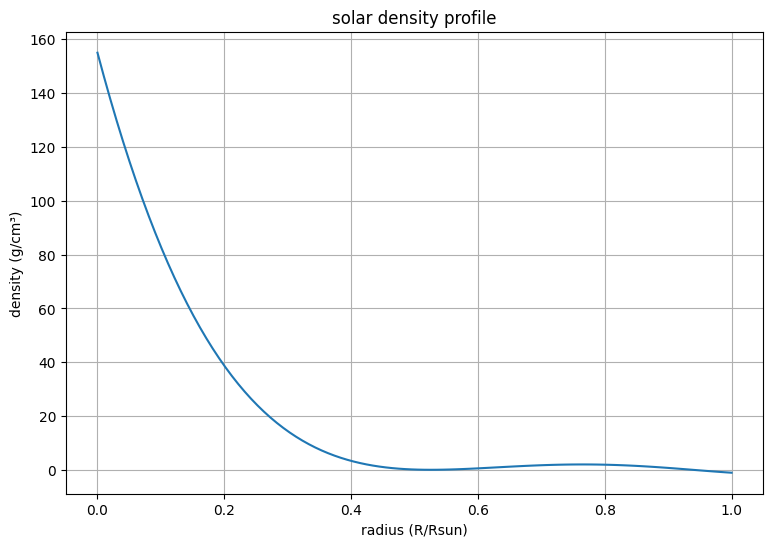

In [28]:
import numpy as np
import matplotlib.pyplot as plt

#a)
R = 6.9e10 #radius
#defining the integrand
def d(x):
    return 519*x**4 - 1630*x**3 + 1844*x**2 - 889*x + 155
def f(x):
    return 4*np.pi*R**3*x**2*d(x) 

#b) sipsons rule witth own implementations
n = 1000
a = 0
b = 1 #suns surface
h = (b-a)/n
s = f(a) + f(b)
for i in range(1, n):
    x = a + i*h
    if i % 2 == 0:
        s += 2*f(x)
    else:
        s += 4*f(x)
M = h/3 * s
print("mass of the sun is =", M, "g")

#c) Find and print the radius at which the density equals 1 g/cm$^3$ (the density of water)
a = 0.8
b = 1.0
for i in range(100):
    m = (a+b)/2
    if (d(a)-1)*(d(m)-1) < 0:
        b = m
    else:
        a = m
print("radius =", m)
print("radius in cm =", m*R)

#d) plot the density profile
x = np.linspace(0, 1, 100)
plt.figure(figsize=(9, 6))
plt.plot(x, d(x))
plt.xlabel("radius (R/Rsun)")
plt.ylabel("density (g/cm³)")
plt.title("solar density profile")
plt.grid()
plt.show()

## Exercise 2. Find the boundary of the Sun's convective zone (10 Points)


In solar-like stars, convection sets in when the magnitude of the temperature gradient exceeds the adiabatic temperature gradient:

$$
\left|\frac{dT}{dx}\right|>\frac{g(x)}{c_p(x)}.
$$

Here, $g(x)$ is the gravitational acceleration, $c_p(x)$ is the specific heat capacity at constant pressure, and $x=r/R_\odot$ is the dimensionless radius. The solar radius is $R_\odot=6.96\times10^8\,\mathrm{m}$. The following simplified model of the Sun is valid for $0.55\leq x\leq0.85$.

The temperature profile is approximated by

$$
T(x)=2.2\times10^6-R_\odot\left[
0.015(x-0.713)
+0.006(x-0.713)^2
+0.010(x-0.713)^3
\right]\ \mathrm{K}.
$$

The adiabatic temperature gradient is approximated by

$$
\frac{g(x)}{c_p(x)}
=0.015[1-0.2(x-0.713)]\ \mathrm{K/m}.
$$

**Hint:** you get an easy expression for the for the radial temperature gradient $dT/dy = -(0.015 + 0.012y + 0.030y^2)$ if you assume $y = x - 0.713$. Just don't forget to subtract 0.713 from the value of $x$ when calculating the derivative.

(**a**) Define the function whose root corresponds to the boundary between the radiative and convective regions (**2 points**)

(**b**) Use a numerical root-finding algorithm (the bisection method) to determine the radius at which the convection begins. Use the interval $0.6\leq x\leq0.8$ and an accuracy of $10^{-5}$ (**5 points** if you use your own function, **1 point** if you use an embedded python function)

(**c**) Print your result from **b** in units of the solar radius and in meters (**1 point**)

(**d**) Plot both temperature gradients ($dT/dx$ and the adiabatic gradient) as functions of \(x\) and indicate the boundary between the radiative and convective regions (**2 points**)

f(a) = -0.0016479300000000006
f(b) = 0.0026180699999999984
radius in solar radii = 0.7129913330078125
radius in meters = 496241967.7734375


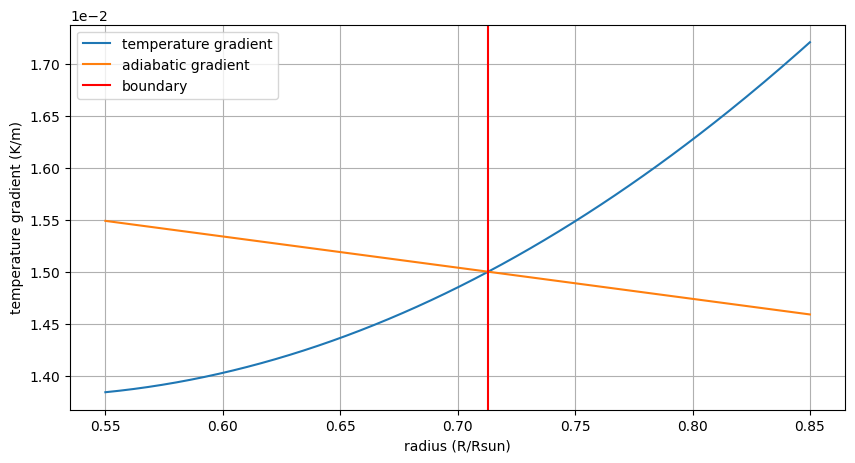

In [29]:
from scipy.optimize import bisect

#a) Define the function whose root corresponds to the boundary between the radiative and convective regions
def grad_T(x):
    y = x - 0.713
    return 0.015 + 0.012*y + 0.030*y**2
def grad_ad(x):
    y = x - 0.713
    return 0.015*(1 - 0.2*y)
def f(x):
    return grad_T(x) - grad_ad(x)

#b) bisection method to determine where convection begins
a = 0.55
b = 0.85
print("f(a) =", f(a))
print("f(b) =", f(b))
root = bisect(f, a, b, xtol=1e-5)

#c) radius in solar radii and meters
R = 6.96e8
print("radius in solar radii =", root)
print("radius in meters =", root * R)

#d) plot both temperature gradients + indicate the boundary between the radiative and convective regions
x = np.linspace(0.55, 0.85, 200)
plt.figure(figsize=(10, 5))
plt.plot(x, grad_T(x), label="temperature gradient")
plt.plot(x, grad_ad(x), label="adiabatic gradient")
plt.axvline(root, color="red", linestyle="-", label="boundary") 
plt.xlabel("radius (R/Rsun)")
plt.ylabel("temperature gradient (K/m)")
plt.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
plt.legend()
plt.grid()
plt.show()